In [1]:
print('hello')

hello


SQL Database तैयार है!

--- Pandas DataFrame ---
   order_id     product     category  quantity    price order_date  \
0         1      Laptop  Electronics         1  50000.0 2026-01-15   
1         2       Shirt     Clothing         2   1200.0 2026-01-16   
2         3  Headphones  Electronics         1   2500.0 2026-02-10   
3         4       Jeans     Clothing         1   2000.0 2026-02-15   
4         5  Smartwatch  Electronics         3   4000.0 2026-03-05   
5         6       Shoes     Clothing         1   3000.0 2026-03-12   

   total_sales  
0      50000.0  
1       2400.0  
2       2500.0  
3       2000.0  
4      12000.0  
5       3000.0  


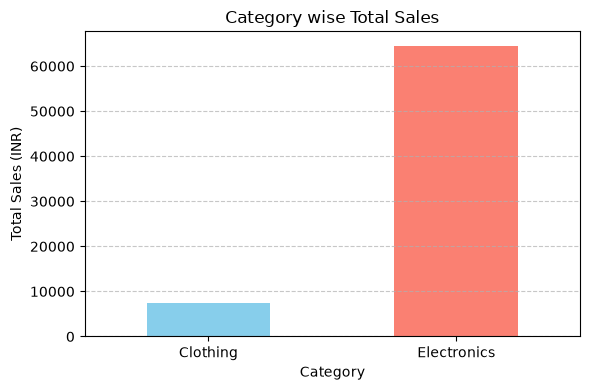

In [4]:
!pip install pandas matplotlib
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect(':memory:')
cursor = conn.cursor()

cursor.execute('''
CREATE TABLE sales (
    order_id INTEGER,
    product TEXT,
    category TEXT,
    quantity INTEGER,
    price REAL,
    order_date TEXT
)
''')

sample_data = [
    (1, 'Laptop', 'Electronics', 1, 50000, '2026-01-15'),
    (2, 'Shirt', 'Clothing', 2, 1200, '2026-01-16'),
    (3, 'Headphones', 'Electronics', 1, 2500, '2026-02-10'),
    (4, 'Jeans', 'Clothing', 1, 2000, '2026-02-15'),
    (5, 'Smartwatch', 'Electronics', 3, 4000, '2026-03-05'),
    (6, 'Shoes', 'Clothing', 1, 3000, '2026-03-12')
]
cursor.executemany('INSERT INTO sales VALUES (?,?,?,?,?,?)', sample_data)
conn.commit()
print("SQL Database तैयार है!")
query = "SELECT * FROM sales"
df = pd.read_sql_query(query, conn)

df['total_sales'] = df['quantity'] * df['price']

df['order_date'] = pd.to_datetime(df['order_date'])

print(df)
category_sales = df.groupby('category')['total_sales'].sum()

plt.figure(figsize=(6, 4))
category_sales.plot(kind='bar', color=['skyblue', 'salmon'])

plt.title('Category wise Total Sales')
plt.xlabel('Category')
plt.ylabel('Total Sales (INR)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

conn.close()